In [1]:
%matplotlib widget

In [2]:
from ModelSimlink import RadiativeTransitions
from standard_imports import *
from loaders import index
from plots import adv_plt, splt, interactive
from scipy.optimize import curve_fit

Call %matplotlib widget
Remember to select "cambiare presentazione" -> "application" in the cells output when you want interactive mode


In [3]:
data = index.load_index_and_data( "TestData/RfPen/20230620" ) + index.load_index_and_data( "TestData/PlasmaBIC/20241031" )
data = [ data[4], data[12] ]

Avantes spectrum TestData/RfPen/20230620\New Experiment0005.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0006.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0007.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0008.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0013.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0014.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0015.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0016.Raw8 normalized by a factor of 0.200000 s
8 rows loaded
Avantes spectrum TestData/PlasmaBIC/20241031\101_6us.RAW8 normalized by a factor of 0.400000 s
Avantes spectrum TestData/PlasmaBIC/20241031\102_6us.RAW8 normalized by a f

Initializing class Levels


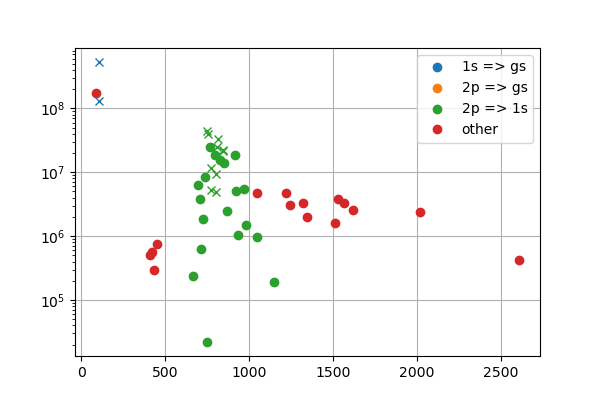

In [4]:
colors = adv_plt.list_colors()
lines_list = RadiativeTransitions.RadiativeTransitions().linesList()

for l in lines_list:
    if( l['from'].startswith('1s') and l['to'] == 'gs' ):
        l['color'] = colors[0]
    elif( l['from'].startswith('2p') and l['to'] == 'gs' ):
        l['color'] = colors[1]
    elif( l['from'].startswith('2p') and l['to'].startswith('1s') ):
        l['color'] = colors[2]
    else:
        l['color'] = colors[3]
    l['marker'] = 'o'

for i in range( len( lines_list ) - 2 ):
    if( lines_list[i+1]['wl'] - lines_list[i]['wl'] < 2 ):
        lines_list[i]['marker'] = 'x'
        lines_list[i+1]['marker'] = 'x'

colors_legend = [ '1s => gs', '2p => gs', '2p => 1s', 'other']

splt.init()

for l in lines_list:
    plt.plot( l['wl'], l['A'], color=l['color'], marker = l['marker'] )
for col, leg in zip( colors, colors_legend ):
    plt.plot( [], [], 'o', color=col, label=leg )

plt.legend()
plt.yscale('log')

lines_selected = [ l for l in lines_list if l['marker'] == 'o' and l['color'] == colors[2] ]
wls_selected = [ l['wl'] for l in lines_selected ]

In [5]:
for l in lines_list:
    print( l['from'], l['to'], f"{l['wl']:.5f}", f"{l['A']:.1e}",sep = '\t' )

3d+2s	gs	87.96880	1.7e+08
1s2	gs	104.81844	5.3e+08
1s4	gs	106.66237	1.3e+08
3p	1s5	410.40496	5.1e+05
3p	1s4	420.88749	5.6e+05
3p	1s3	435.61171	3.0e+05
3p	1s2	452.28336	7.4e+05
2p1	1s4	667.88986	2.4e+05
2p2	1s5	696.71153	6.4e+06
2p3	1s5	706.89267	3.8e+06
2p4	1s5	714.87690	6.3e+05
2p2	1s4	727.46931	1.8e+06
2p3	1s4	738.57639	8.5e+06
2p4	1s4	747.29681	2.2e+04
2p1	1s2	750.56801	4.5e+07
2p5	1s4	751.64659	4.0e+07
2p6	1s5	763.69485	2.4e+07
2p7	1s5	772.56241	5.2e+06
2p2	1s3	772.60708	1.2e+07
2p4	1s3	795.00929	1.9e+07
2p6	1s4	800.80870	4.9e+06
2p8	1s5	801.67181	9.3e+06
2p7	1s4	810.56459	2.5e+07
2p9	1s5	811.72674	3.3e+07
2p2	1s2	826.65133	1.5e+07
2p3	1s2	841.02343	2.2e+07
2p8	1s4	842.66770	2.2e+07
2p4	1s2	852.34937	1.4e+07
2p7	1s3	867.00302	2.4e+06
2p10	1s5	912.51615	1.9e+07
2p6	1s2	922.67170	5.0e+06
2p7	1s2	935.64677	1.1e+06
2p10	1s4	966.01074	5.4e+06
2p8	1s2	978.68537	1.5e+06
3d+2s	2p10	1044.81823	4.7e+06
2p10	1s3	1047.25671	9.8e+05
2p10	1s2	1149.08637	1.9e+05
3d+2s	2p9	1217.97693	4.7e+06
3d+2s

In [6]:
for lvl in np.unique( [ l['from'] for l in lines_selected ] ):
    print( lvl, "\t", [ f"{l['wl']:.1f}" for l in lines_selected if l['from'] == lvl ] )

2p1 	 ['667.9']
2p10 	 ['912.5', '966.0', '1047.3', '1149.1']
2p2 	 ['696.7', '727.5', '826.7']
2p3 	 ['706.9', '738.6']
2p4 	 ['714.9', '747.3', '795.0', '852.3']
2p6 	 ['763.7', '922.7']
2p7 	 ['867.0', '935.6']
2p8 	 ['978.7']


In [7]:
def gauss(x, H, A, x0, sigma):
    return H + A / np.sqrt(2 * np.pi) / sigma * np.exp(-(x - x0)**2 / (2 * sigma**2))


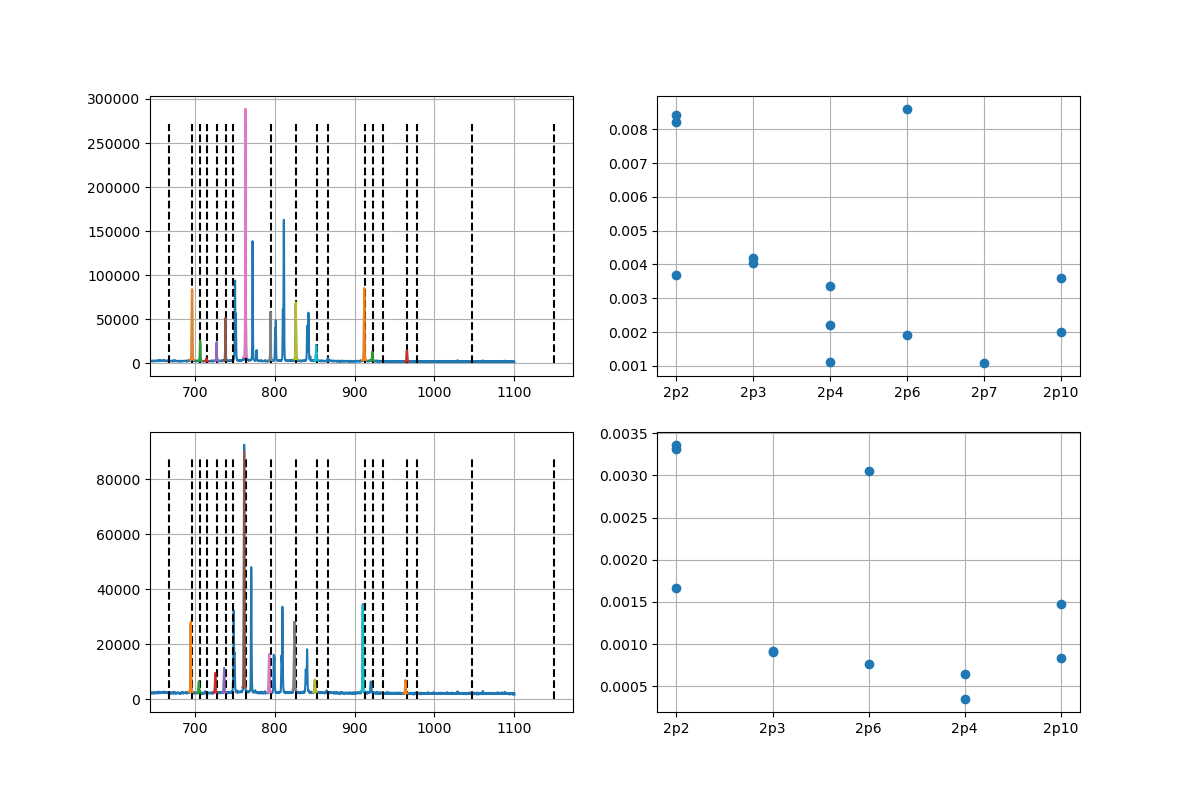

In [8]:
splt.init( len( data ), 2 )
for d in data:
    # Find the peaks and fit
    offset = -2
    baseline = np.mean( d['avantes']['int'][:40] )

    # Plot data
    splt.next()
    plt.plot( d['avantes']['wl'], d['avantes']['int'] )
    plt.xlim( np.min( wls_selected ) - 0.05 * np.ptp( wls_selected ), np.max( wls_selected ) + 0.05 * np.ptp( wls_selected ) )
    ylim = plt.ylim()
    for wl in wls_selected:
        plt.plot( [ wl, wl ], [0, 0.9 * ylim[1] ], 'k--' )

    # Interp line by line
    d['est_densities'] = []
    for l in lines_selected:
        idx_where = np.where( d['avantes']['wl'] > l['wl'] + offset + 0.5 )[0]
        if( len( idx_where ) < 1 ):
            continue
        idx = np.min( idx_where )
        idx_max = np.argmax( d['avantes']['int'][idx-3:idx+4] ) + idx - 3
        if( d['avantes']['int'][idx_max] < baseline * 2 ):
            continue

        delta = 8
        p, _ = curve_fit(gauss, d['avantes']['wl'][idx_max-delta:idx_max+delta+1], d['avantes']['int'][idx_max-delta:idx_max+delta+1],
                            p0=[ baseline, d['avantes']['int'][idx_max], l['wl'] + offset, 1 ])
        
        xs = np.linspace( d['avantes']['wl'][idx_max-delta], d['avantes']['wl'][idx_max+delta], 100 )
        plt.plot( xs, gauss( xs, *p ) )
        d['est_densities'].append(
            { 'level': l['from'], 'density': p[1] / l['A'] }
        )


    splt.next()
    plt.plot(
        [ i['level'] for i in d['est_densities'] ],
        [ i['density'] for i in d['est_densities'] ],
        'o'
    )